NAME: Anna Bernardi

DATE: 30/09/2025


# Introduction 

This notebook presents the use of resampling methods to evaluate the perfomance of a given statistical learnig method to then choose the better level of flexibility.



# Code requirements 

In [76]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error
from scipy.optimize import minimize

# Data Wrangling

In [3]:
df = pd.read_csv('pollution_cleaneddata.csv')
df.head()

,PREC,JANT,JULT,OVR65,POPN,EDUC,HOUS,DENS,NONW,WWDRK,POOR,HC,NOX,SO@,HUMID,MORT
0,36.0,27.0,71.0,8.1,3.34,11.4,81.5,3243.0,8.8,42.6,11.7,21.0,15.0,59.0,59.0,921.870
1,35.0,23.0,72.0,11.1,3.14,11.0,78.8,4281.0,3.5,50.7,14.4,8.0,10.0,39.0,57.0,997.875
2,44.0,29.0,74.0,10.4,3.21,9.8,81.6,4260.0,0.8,39.4,12.4,6.0,6.0,33.0,54.0,962.354
3,47.0,45.0,79.0,6.5,3.41,11.1,77.5,3125.0,27.1,50.2,20.6,18.0,8.0,24.0,56.0,982.291
4,43.0,35.0,77.0,7.6,3.44,9.6,84.6,6441.0,24.4,43.7,14.3,43.0,38.0,206.0,55.0,1071.289


We will not use the entire dataframe because we're interested in specifing a model that predicts the mortality as a function of the average July temperature in degrees F

In [11]:
#selecting a smaller dataframe with the data we need 
df = df[['JULT', 'MORT']]


Text(0, 0.5, 'Total age-adjusted mortality rate per 100,000')

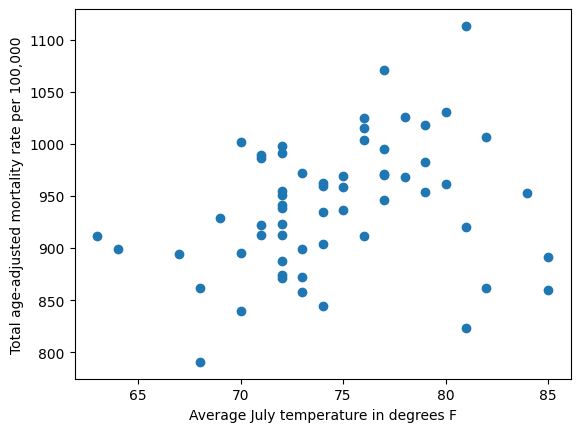

In [8]:
plt.scatter(df['JULT'],df['MORT'])
plt.xlabel('Average July temperature in degrees F')
plt.ylabel('Total age-adjusted mortality rate per 100,000')

# Cross validation 

## Model
Given $y_i$ the mortality rate and $x_i$ the average July temperature, the chosen model is:
$$y_i = \beta _0 + \beta _1x_i+\beta _2x_i^2+...+\beta _px_i^p+\epsilon _i$$
With the degree of the polinomial p to be chosen from 1 to 4.

## Validation set approach

For the validation set approach we split the data into a training set and a validation set of equal size. 

In [ ]:
train, validation = train_test_split(df, test_size=0.50, random_state = 42)

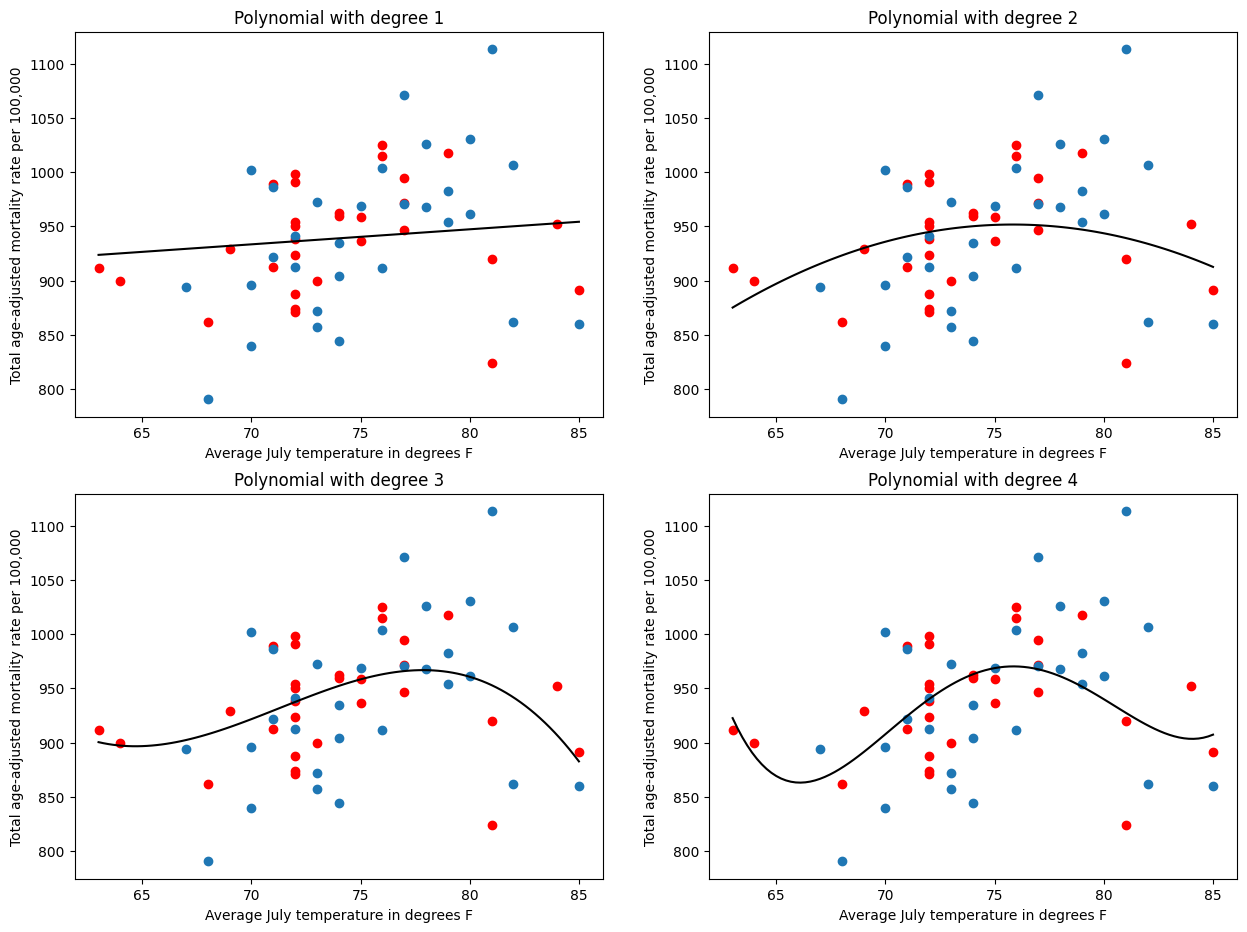

In [56]:
poly_deg = np.array([1,2,3,4])

#to store MSE values:
train_mse = []
val_mse = []


fig,ax=plt.subplots(2,2,figsize=(15,11))
ax = ax.flatten()

for i,d in enumerate(poly_deg):
    model = np.poly1d(np.polyfit(train['JULT'],train['MORT'],d))
    line = np.linspace(df.min(axis=0)['JULT'], df.max(axis=0)['JULT'], 100)

    #predictions:
    y_pred_train = model(train['JULT'])
    y_pred_val = model(validation['JULT'])

    # MSE
    mse_train = mean_squared_error(train['MORT'], y_pred_train)
    mse_val   = mean_squared_error(validation['MORT'], y_pred_val)
    
    train_mse.append(mse_train)
    val_mse.append(mse_val)

    ax[i].scatter(train['JULT'],train['MORT'], c='red')
    ax[i].scatter(validation['JULT'],validation['MORT'])
    ax[i].plot(line, model(line), color='black')
    ax[i].set_title(f'Polynomial with degree {d}')
    ax[i].set_xlabel('Average July temperature in degrees F')
    ax[i].set_ylabel('Total age-adjusted mortality rate per 100,000')

### MSE

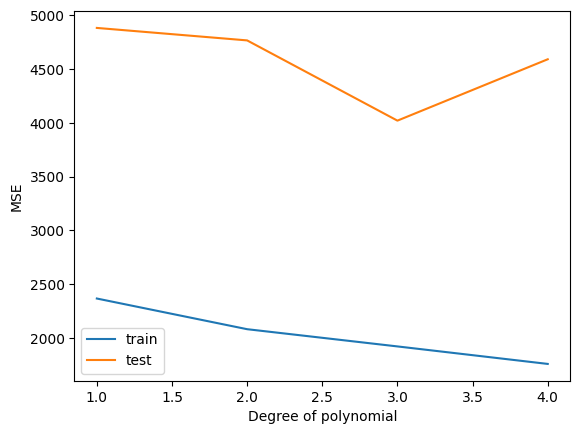

In [57]:
plt.plot(poly_deg, train_mse, label='train')
plt.plot(poly_deg, val_mse, label='test')
plt.xlabel('Degree of polynomial')
plt.ylabel('MSE')
plt.legend()

For the graph the smallest $MSE_{test}$ is obtained with a polynomial of degree equal to 3, and that will give us predictions with the smallest expected variance on new data.


We'll now repeat the procedure ten times but with other random seeds

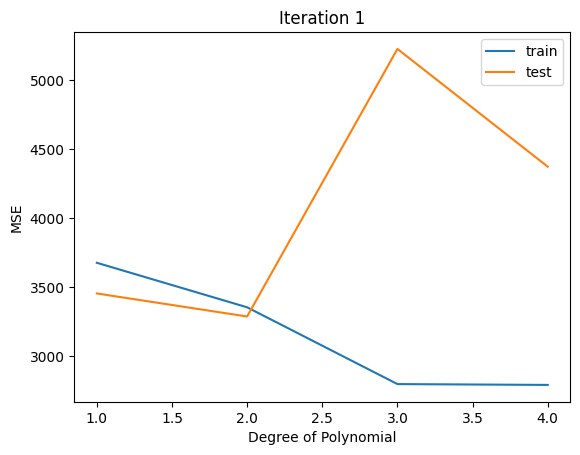

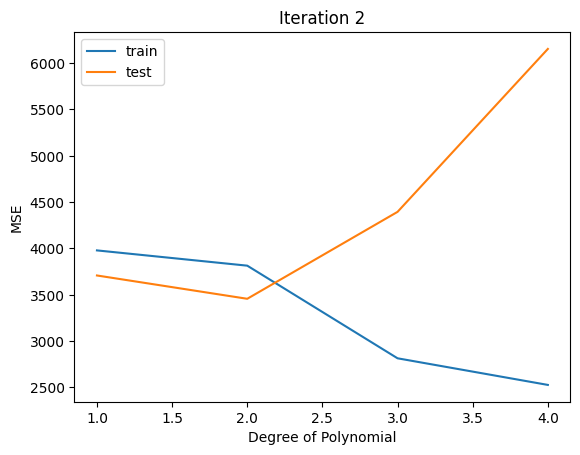

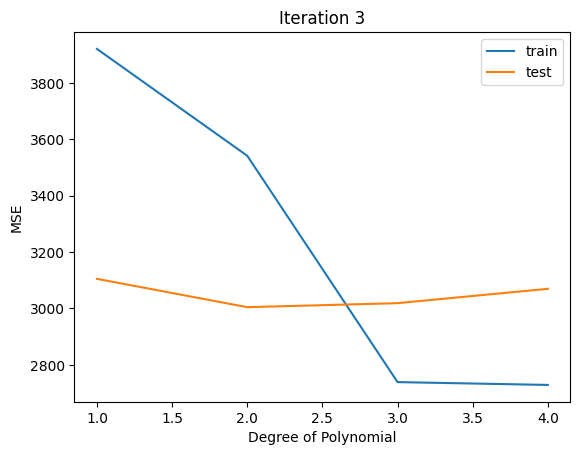

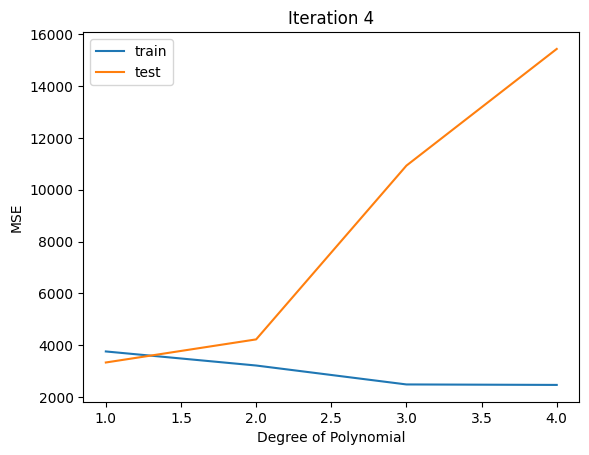

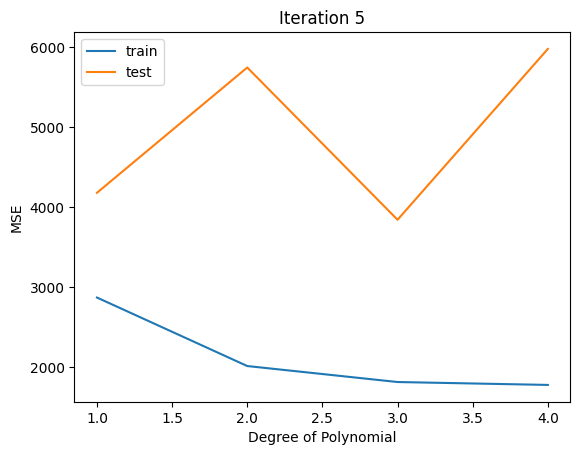

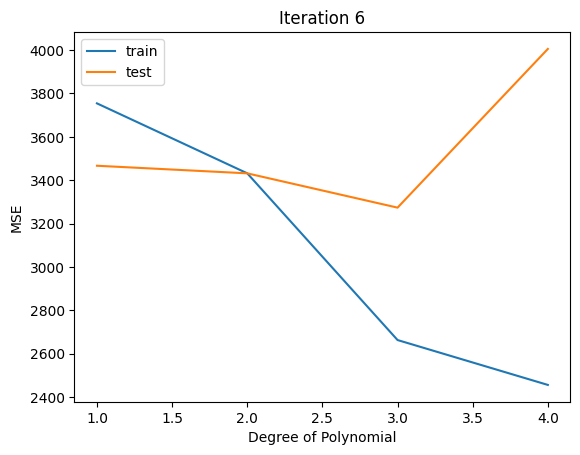

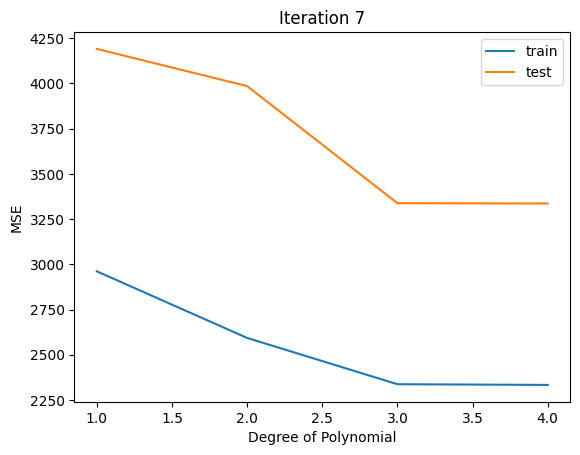

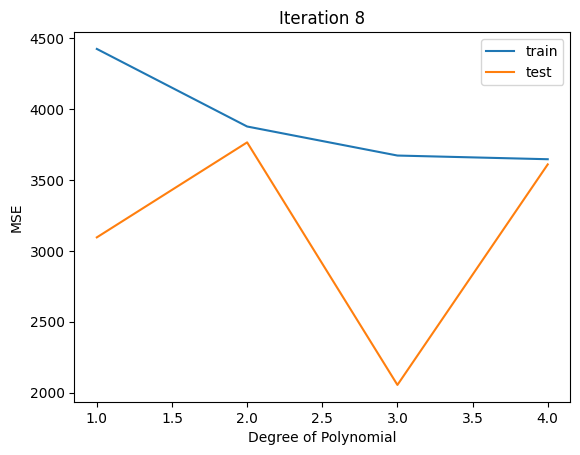

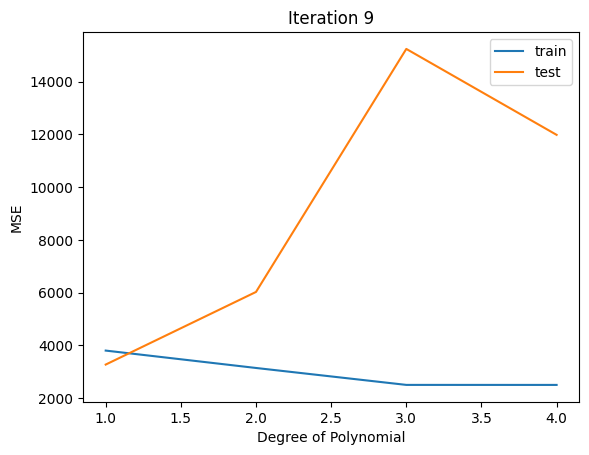

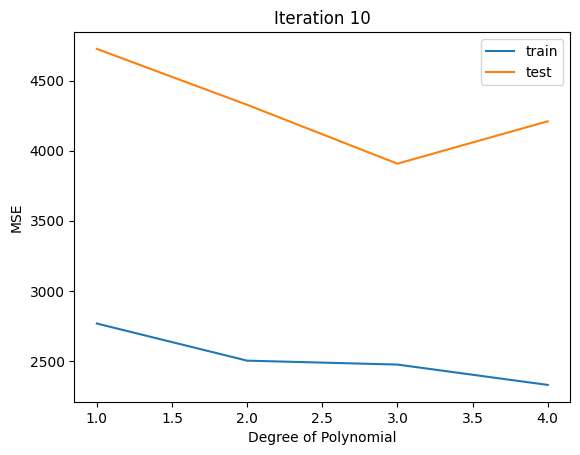

In [72]:
n_repeats = 10
results = []

for i in range(n_repeats):
    train, validation = train_test_split(df, test_size=0.50, shuffle=True, random_state=None)
    
    train_mse = []
    val_mse   = []
    
    for d in poly_deg:
        model = np.poly1d(np.polyfit(train['JULT'], train['MORT'], d))
        
        y_pred_train = model(train['JULT'])
        y_pred_val   = model(validation['JULT'])
        
        mse_train = mean_squared_error(train['MORT'], y_pred_train)
        mse_val   = mean_squared_error(validation['MORT'], y_pred_val)
        
        train_mse.append(mse_train)
        val_mse.append(mse_val)
        
        results.append((d, mse_train, mse_val))
    
    plt.figure()
    plt.plot(poly_deg, train_mse, label='train')
    plt.plot(poly_deg, val_mse, label='test')
    plt.xlabel('Degree of Polynomial')
    plt.ylabel('MSE')
    plt.title(f'Iteration {i+1}')
    plt.legend()
    plt.show()


For most iteration with random seeds, the polynomial with degree 2 or 3 produced the smaller $MSE_{test}$

## K-fold cross-validation
 
We'll now select 3 as the degree for the polynomial, to then estimate the variance of predictions using the K-fold cross-validation approach with $K = 3$ 

In [58]:
kf = KFold(n_splits=3, random_state=42, shuffle=True)  #train/test indices to split data in train/test sets


train_mse_list = []
val_mse_list = []

for train_index, test_index in kf.split(df):
    train = df.iloc[train_index]
    test  = df.iloc[test_index]
    model = np.poly1d(np.polyfit(train['JULT'],train['MORT'],3))

    #predictions:
    y_pred_train = model(train['JULT'])
    y_pred_val = model(validation['JULT'])

    #MSE
    mse_train = mean_squared_error(train['MORT'], y_pred_train)
    mse_val   = mean_squared_error(validation['MORT'], y_pred_val)
    train_mse_list.append(mse_train)
    val_mse_list.append(mse_val)

print(f'The MSE for the training data is {np.mean(train_mse_list):.2f}')
print(f'The MSE for the validation data is {np.mean(val_mse_list):.2f}')

The MSE for the training data is 2758.15
The MSE for the validation data is 3583.18


We'll do the same ten times but with other random seeds.

In [62]:
n_repeats = 10  
results = []

for i in range(n_repeats):
    kf = KFold(n_splits=3, shuffle=True, random_state=None)
    
    train_mse_list = []
    val_mse_list = []
    
    for train_index, test_index in kf.split(df):
        train = df.iloc[train_index]
        test  = df.iloc[test_index]
        
        model = np.poly1d(np.polyfit(train['JULT'], train['MORT'], 3))
        
        #predictions
        y_pred_train = model(train['JULT'])
        y_pred_val   = model(test['JULT'])
        
        #MSE 
        train_mse_list.append(mean_squared_error(train['MORT'], y_pred_train))
        val_mse_list.append(mean_squared_error(test['MORT'], y_pred_val))
    
    avg_train = np.mean(train_mse_list)
    avg_val   = np.mean(val_mse_list)
    
    results.append((avg_train, avg_val))
    print(f"Iteration {i+1}: Train MSE = {avg_train:.2f}, Validation MSE = {avg_val:.2f}")



Iteration 1: Train MSE = 2651.69, Validation MSE = 5853.29
Iteration 2: Train MSE = 2732.60, Validation MSE = 3406.01
Iteration 3: Train MSE = 2683.06, Validation MSE = 3358.43
Iteration 4: Train MSE = 2715.26, Validation MSE = 3232.46
Iteration 5: Train MSE = 2783.11, Validation MSE = 2857.18
Iteration 6: Train MSE = 2760.15, Validation MSE = 3470.04
Iteration 7: Train MSE = 2776.16, Validation MSE = 2978.13
Iteration 8: Train MSE = 2778.27, Validation MSE = 2886.84
Iteration 9: Train MSE = 2788.29, Validation MSE = 2832.37
Iteration 10: Train MSE = 2724.82, Validation MSE = 3166.09


We get a different result each time because the model is fitted on slightly different data choosing different seeds.

# The bootstrap

### Model 

For the given data: Y= total bird counts; X: years.

Y follows the Poisson ditribution $Y|x_i \sim Po(\lambda (x_i))$

The log of the intensity can be modelled as:
$\log(\lambda (x_i) )= \beta _0 + \beta _1 x_i$

The Poisson model that will be used was fitted with maximum likelihood.

Text(0.5, 1.0, 'Bird count per year')

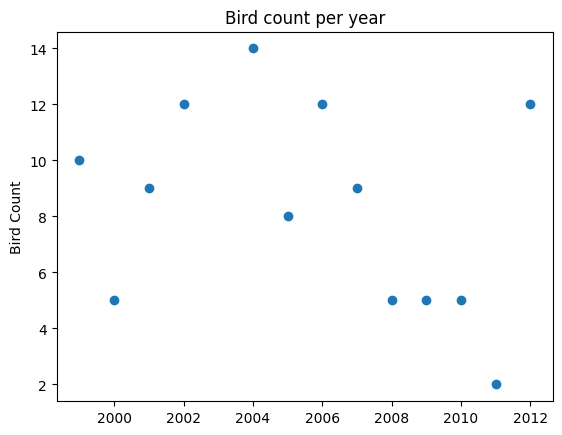

In [74]:
df = pd.read_csv('bird_count.csv')
df.sort_values(by=['yr'], inplace=True)
df.head()
plt.scatter(df['yr'],df['count'])
plt.ylabel('Bird Count')
plt.title("Bird count per year")

### Maximum likelihood estimation

In [78]:
def log_likelihood(params,x,y):
    beta_0, beta_1 = params

    lambda_hat = beta_0 + beta_1 * x
    
    #clipping to avoid exp overflow
    lambda_hat = np.clip(lambda_hat, -500, 500)
    
    result = np.sum(y * lambda_hat - np.exp(lambda_hat))
    
    return result

x = df['yr'].to_numpy()
y = df['count'].to_numpy()

x_norm = df['yr'] - 1999 
df['x_norm'] = x_norm 

#initial guess
init = np.array([0.0, 0.0])

res = minimize(lambda p: -log_likelihood(p, x_norm, y), init)  #to maximize the function I'm minimizing the -log likelihood
beta0_hat, beta1_hat = res.x


print("The parameters after the optimazation are: beta_0:", np.round(beta0_hat, 3), "; beta_1:", np.round(beta1_hat, 3))


The parameters after the optimazation are: beta_0: 2.325 ; beta_1: -0.032


So for the given data the estimated $\hat\beta _1=-0.032$

### Estimation of $\beta _1$ with Bootstrap

In [ ]:
n_bootstrap = 100
bootstrap_slopes = []


for i in range(n_bootstrap):
    #resampling rows with replacement
    sample = df.sample(n=len(df), replace=True)
    
    x_sample = sample['x_norm'].to_numpy()
    y_sample = sample['count'].to_numpy()
    
    res = minimize(lambda p: -log_likelihood(p, x_sample, y_sample), init)
    beta0_hat_boot, beta1_hat_boot = res.x
    
    bootstrap_slopes.append(beta1_hat_boot)

# Standard error
se_slope = np.std(bootstrap_slopes, ddof=1)
print(f"Bootstrap estimate of standard error for slope with {n_bootstrap} samples is: {se_slope:.4f}")


Bootstrap estimate of standard error for slope with 100 samples is: 0.0332
